<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory Ch 4 Figures — Colab Notebook
**Gauge Theory · Chapter 4: Lattice Gauge Theory**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §4.1   | Lattice geometry, dispersion relation, continuum limit |
| fig02  | §4.2.3 | Strong coupling: plaquette tiling, string tension |
| fig03  | §4.3   | Fermion doubling: dispersion, BZ corners, chirality |
| fig04  | §4.4.1 | Domain wall fermions: 5D geometry, zero mode profiles |
| fig05  | §4.4.3 | Ginsparg-Wilson: GW circle, index, mass renorm. |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, Rectangle, FancyBboxPatch
from matplotlib.lines import Line2D
from math import comb
import os

# ── Dark theme (matches tong_dark.scss and the other chapters) ──
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
AMBER  = '#e8a838'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 13, 'axes.titlesize': 14, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMBER, 'legend.framealpha': 0.5,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.5,
    'axes.linewidth': 1.4, 'figure.dpi': 110,
    'legend.facecolor': BG,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')


Setup complete.


---
## fig01 · Lattice Geometry & Dispersion (§4.1)

**Left**: 2D hypercubic lattice with sites and links  
**Middle**: Lattice dispersion $\hat{p}=\frac{2}{a}\sin(pa/2)$ vs continuum $p$  
**Right**: Continuum limit — $\hat{p}/p\to 1$ as $a\to 0$

  saved -> figures/ch04/fig01_lattice_scalar.png


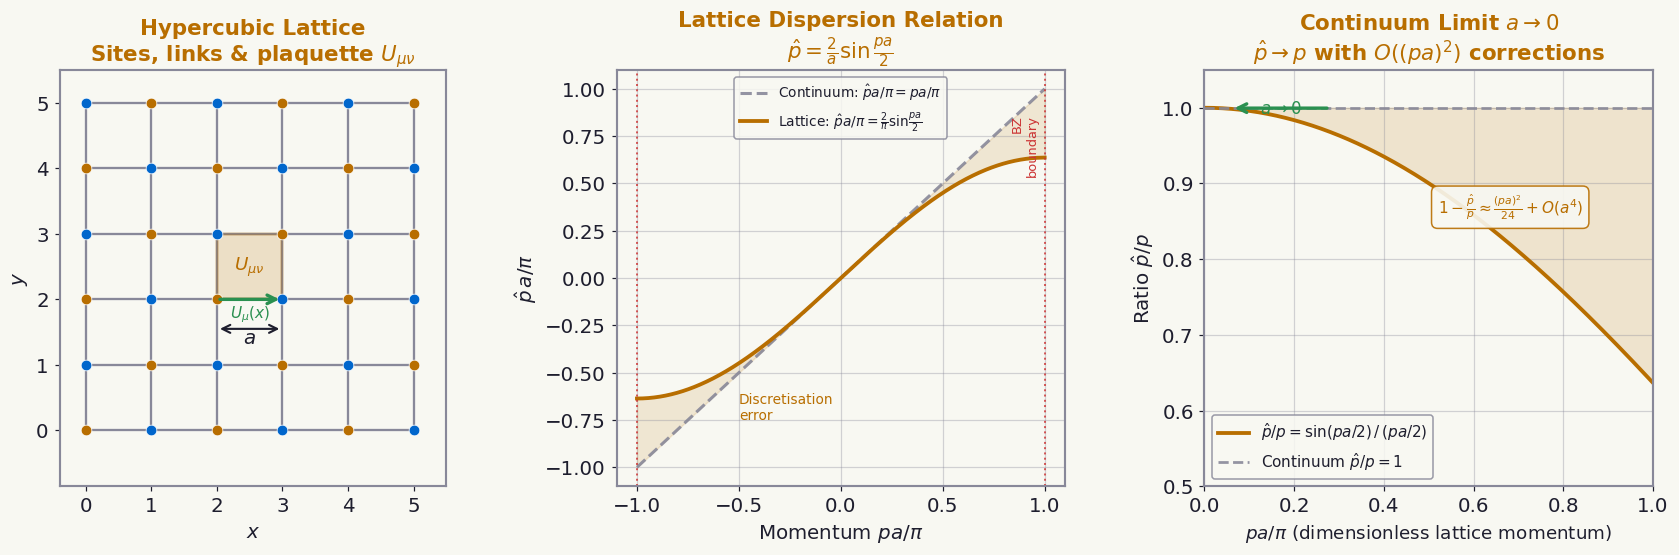

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: 2D hypercubic lattice ────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')

N = 6
a = 1.0

for i in range(N):
    for j in range(N):
        if i < N-1:
            ax.plot([i*a, (i+1)*a], [j*a, j*a], color=EDGE, lw=1.5, zorder=1)
        if j < N-1:
            ax.plot([i*a, i*a], [j*a, (j+1)*a], color=EDGE, lw=1.5, zorder=1)

for i in range(N):
    for j in range(N):
        col = AMBER if (i+j)%2==0 else BLUE
        ax.plot(i*a, j*a, 'o', color=col, ms=7, zorder=3, mec='white', mew=0.5)

px, py = 2, 2
plaq = Rectangle((px*a, py*a), a, a, fill=True, facecolor=AMBER, alpha=0.18,
                  edgecolor=AMBER, lw=2.5, zorder=2)
ax.add_patch(plaq)
ax.text((px+0.5)*a, (py+0.5)*a, r'$U_{\mu\nu}$', ha='center', va='center',
        fontsize=12, color=AMBER, fontweight='bold')

ax.annotate('', xy=((px+1)*a, py*a), xytext=(px*a, py*a),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.2, mutation_scale=14))
ax.text((px+0.5)*a, (py-0.28)*a, r'$U_\mu(x)$', ha='center', fontsize=10, color=GREEN)

ax.annotate('', xy=((px+1)*a, (py-0.45)*a), xytext=(px*a, (py-0.45)*a),
            arrowprops=dict(arrowstyle='<->', color=FG, lw=1.4))
ax.text((px+0.5)*a, (py-0.68)*a, '$a$', ha='center', fontsize=13, color=FG)

ax.set_xlim(-0.4, (N-0.5)*a)
ax.set_ylim(-0.85, (N-0.5)*a)
ax.set_xlabel('$x$', fontsize=13); ax.set_ylabel('$y$', fontsize=13)
ax.set_title('Hypercubic Lattice\nSites, links & plaquette $U_{\\mu\\nu}$', color=AMBER)
ax.set_xticks(range(N)); ax.set_yticks(range(N))

# ── Middle: Dispersion relation ────────────────────────────────────────────
# 수정: y축이 실제로 (2/a)sin(pa/2)를 a/π로 스케일한 값임을 명확히 함
# x축: pa/π ∈ [-1,1],  y축: (2/π)sin(pa/2) — 두 값 모두 무차원
ax2 = axes[1]
ax2.set_facecolor(BG)

pa = np.linspace(-np.pi, np.pi, 500)

# Continuum: hat_p = p  →  (pa)/π
ax2.plot(pa/np.pi, pa/np.pi, color=EDGE, lw=2, ls='--', alpha=0.9,
         label=r'Continuum: $\hat{p}a/\pi = pa/\pi$')

# Lattice: hat_p = (2/a)sin(pa/2)  →  (2/π)sin(pa/2)
phat_scaled = (2/np.pi) * np.sin(pa/2)
ax2.plot(pa/np.pi, phat_scaled, color=AMBER, lw=2.5,
         label=r'Lattice: $\hat{p}a/\pi=\frac{2}{\pi}\sin\!\frac{pa}{2}$')

ax2.axvline(-1, color=RED, lw=1.3, ls=':', alpha=0.8)
ax2.axvline(+1, color=RED, lw=1.3, ls=':', alpha=0.8)
ax2.text(0.97, 0.55, 'BZ\nboundary', fontsize=8.5, color=RED, ha='right', rotation=90)

ax2.fill_between(pa/np.pi, pa/np.pi, phat_scaled, color=AMBER, alpha=0.13)
ax2.text(-0.5, -0.75, 'Discretisation\nerror', fontsize=9, color=AMBER)

ax2.set_xlabel(r'Momentum $pa/\pi$', fontsize=13)
ax2.set_ylabel(r'$\hat{p}\,a/\pi$', fontsize=13)
ax2.set_title('Lattice Dispersion Relation\n' + r'$\hat{p}=\frac{2}{a}\sin\frac{pa}{2}$', color=AMBER)
ax2.legend(fontsize=9)
ax2.set_xlim(-1.1, 1.1); ax2.set_ylim(-1.1, 1.1)
ax2.grid(True, alpha=0.35)

# ── Right: Continuum limit ─────────────────────────────────────────────────
# 수정: y축 레이블을 "ratio = hat_p/p"로 명확히, O(a²) 보정 식 표시
ax3 = axes[2]
ax3.set_facecolor(BG)

pa_vals = np.linspace(1e-6, np.pi, 400)
ratio = np.sin(pa_vals/2) / (pa_vals/2)   # exact: sin(x)/x, x = pa/2

ax3.plot(pa_vals/np.pi, ratio, color=AMBER, lw=2.5,
         label=r'$\hat{p}/p = \sin(pa/2)\,/\,(pa/2)$')
ax3.axhline(1, color=EDGE, lw=1.8, ls='--', alpha=0.9, label=r'Continuum $\hat{p}/p=1$')

ax3.annotate('', xy=(0.06, 0.9995), xytext=(0.28, 0.9995),
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.2, mutation_scale=14))
ax3.text(0.17, 0.992, r'$a\to 0$', fontsize=11, color=GREEN, ha='center')

ax3.fill_between(pa_vals/np.pi, ratio, 1, color=AMBER, alpha=0.15)

# 실제 O(a²) 보정: 1 - sin(x)/x ≈ x²/6 = (pa)²/24
ax3.text(0.52, 0.86,
         r'$1-\frac{\hat{p}}{p}\approx\frac{(pa)^2}{24}+O(a^4)$',
         fontsize=10, color=AMBER,
         bbox=dict(boxstyle='round,pad=0.4', facecolor=BG, edgecolor=AMBER, alpha=0.9))

ax3.set_xlabel(r'$pa/\pi$ (dimensionless lattice momentum)', fontsize=12)
ax3.set_ylabel(r'Ratio $\hat{p}/p$', fontsize=13)
ax3.set_title(r'Continuum Limit $a\to 0$' + '\n' + r'$\hat{p}\to p$ with $O((pa)^2)$ corrections', color=AMBER)
ax3.legend(fontsize=10)
ax3.set_xlim(0, 1); ax3.set_ylim(0.5, 1.05)
ax3.grid(True, alpha=0.35)

plt.tight_layout(pad=1.8)
save('fig01_lattice_scalar.png', fig)


---
## fig02 · Strong Coupling Expansion (§4.2.3)

**Left**: Plaquette tiling of a rectangular Wilson loop  
**Middle**: String tension $\sigma$ vs $\beta=2N/g^2$ (schematic + lattice data trend)  
**Right**: $\log\langle W\rangle$ vs area at strong coupling — area law

  saved -> figures/ch04/fig02_strong_coupling.png


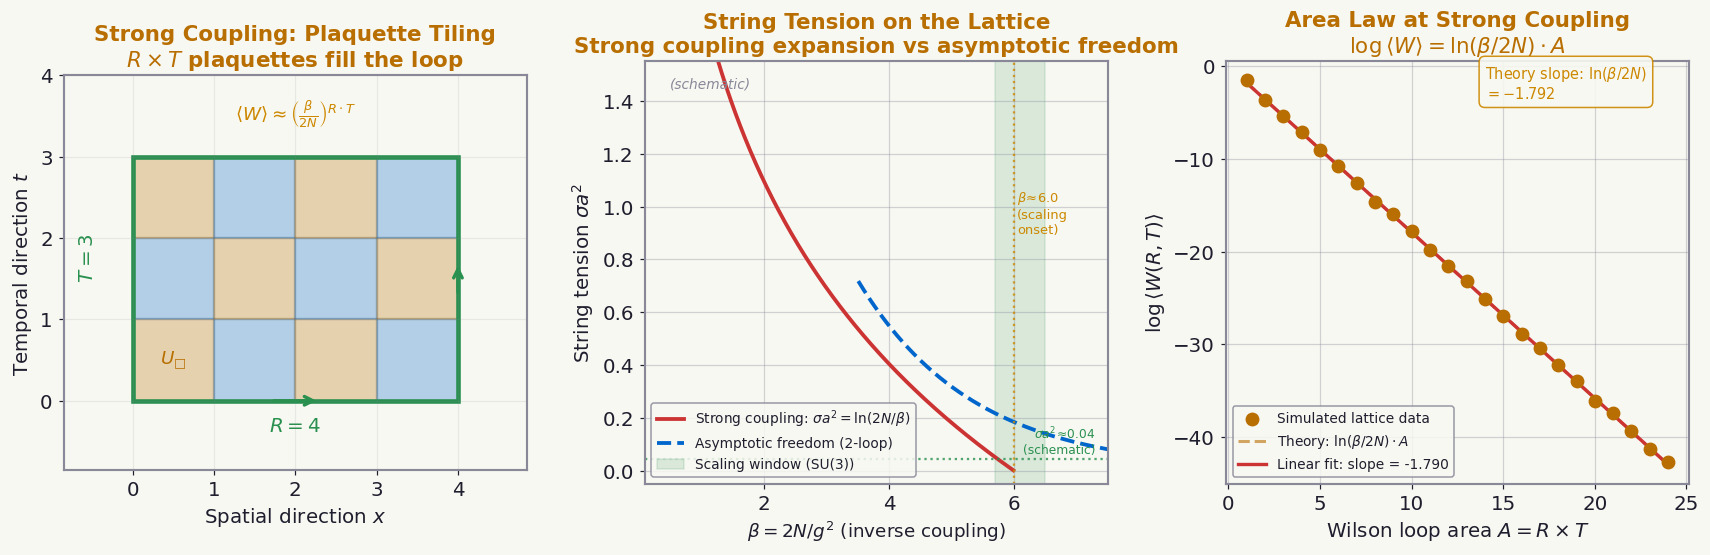

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: Plaquette tiling ─────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')

R_loop, T_loop = 4, 3

for i in range(R_loop):
    for j in range(T_loop):
        col = AMBER if (i+j)%2==0 else BLUE
        rect = Rectangle((i, j), 1, 1, facecolor=col, alpha=0.28,
                          edgecolor=col, lw=1.5)
        ax.add_patch(rect)

loop_rect = Rectangle((0, 0), R_loop, T_loop, fill=False,
                       edgecolor=GREEN, lw=3)
ax.add_patch(loop_rect)

ax.annotate('', xy=(R_loop/2+0.3, 0), xytext=(R_loop/2-0.3, 0),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.2, mutation_scale=14))
ax.annotate('', xy=(R_loop, T_loop/2+0.2), xytext=(R_loop, T_loop/2-0.2),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.2, mutation_scale=14))

ax.text(R_loop/2, -0.38, f'$R={R_loop}$', ha='center', fontsize=13, color=GREEN)
ax.text(-0.55, T_loop/2, f'$T={T_loop}$', ha='center', fontsize=13, color=GREEN, rotation=90)
ax.text(0.5, 0.5, u'$U_\u25a1$', ha='center', va='center', fontsize=12, color=AMBER)
ax.text(R_loop/2, T_loop+0.45,
        r'$\langle W\rangle \approx \left(\frac{\beta}{2N}\right)^{R\cdot T}$',
        ha='center', fontsize=12, color=YELLOW)

ax.set_xlim(-0.85, R_loop+0.85)
ax.set_ylim(-0.85, T_loop+1.0)
ax.set_xlabel('Spatial direction $x$', fontsize=13)
ax.set_ylabel('Temporal direction $t$', fontsize=13)
ax.set_title('Strong Coupling: Plaquette Tiling\n' + r'$R\times T$ plaquettes fill the loop', color=AMBER)
ax.grid(True, alpha=0.15)

# ── Middle: String tension vs beta ────────────────────────────────────────
# 수정: strong coupling 결과는 β < 2N 에서만 물리적.
# 두 곡선이 실제로 연결되지 않음(상전이 없음) — 단순 모식도임을 명시
ax2 = axes[1]
ax2.set_facecolor(BG)

N_col = 3
beta_arr = np.linspace(0.1, 7.5, 500)

# Strong coupling: σa² = -ln(β/2N) = ln(2N/β), valid for β < 2N=6
sigma_strong = np.where(beta_arr < 2*N_col,
                        np.log(2*N_col / np.maximum(beta_arr, 0.01)),
                        np.nan)

# Weak coupling / continuum scaling: σa² ~ Λ²_lat a²
# 2-loop: σa² ∝ exp(-β/b0) with b0 = 11N/3 for SU(N) (pure gauge)
b0_val = 11*N_col/3
# Normalise to join approximately at β~4
sigma_weak = np.where(beta_arr > 3.5,
                      0.55 * np.exp(-6*(beta_arr - 4.0)/b0_val), np.nan)

ax2.plot(beta_arr, sigma_strong, color=RED, lw=2.5,
         label=r'Strong coupling: $\sigma a^2=\ln(2N/\beta)$')
ax2.plot(beta_arr, sigma_weak, color=BLUE, lw=2.5, ls='--',
         label=r'Asymptotic freedom (2-loop)')

# Physical window (continuum scaling window for SU(3))
ax2.axvspan(5.7, 6.5, color=GREEN, alpha=0.15, label=r'Scaling window (SU(3))')

# β_c annotation: continuum scaling onset
ax2.axvline(6.0, color=YELLOW, lw=1.5, ls=':', alpha=0.8)
ax2.text(6.05, 0.9, r'$\beta\!\approx\!6.0$' + '\n(scaling\nonset)', fontsize=8.5, color=YELLOW)

# σ_phys horizontal guide — lattice value at β~6: σa²≈0.044 for a≈0.1 fm
ax2.axhline(0.044, color=GREEN, lw=1.5, ls=':', alpha=0.8)
ax2.text(7.3, 0.065, r'$\sigma a^2\!\approx\!0.04$'+'\n(schematic)', fontsize=8, color=GREEN, ha='right')

ax2.set_xlabel(r'$\beta = 2N/g^2$ (inverse coupling)', fontsize=12)
ax2.set_ylabel(r'String tension $\sigma a^2$', fontsize=13)
ax2.set_title('String Tension on the Lattice\n' + r'Strong coupling expansion vs asymptotic freedom', color=AMBER)
ax2.legend(fontsize=9)
ax2.set_xlim(0.1, 7.5); ax2.set_ylim(-0.05, 1.55)
ax2.grid(True, alpha=0.35)
ax2.text(0.5, 1.45, '(schematic)', fontsize=9, color=EDGE, style='italic')

# ── Right: Area law log<W> vs area ────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

beta_sc = 1.0
N_sc = 3
log_ratio = np.log(beta_sc / (2*N_sc))  # = ln(1/6) ≈ -1.792

area_vals = np.arange(1, 25)
logW_sc = log_ratio * area_vals

np.random.seed(7)
noise = np.random.normal(0, 0.15, len(area_vals))
logW_data = logW_sc + noise

ax3.scatter(area_vals, logW_data, color=AMBER, s=65, zorder=5,
            label='Simulated lattice data')
ax3.plot(area_vals, logW_sc, color=AMBER, lw=2, ls='--', alpha=0.6,
         label=r'Theory: $\ln(\beta/2N)\cdot A$')

fit_coef = np.polyfit(area_vals, logW_data, 1)
ax3.plot(area_vals, np.polyval(fit_coef, area_vals), color=RED, lw=2.2,
         label=f'Linear fit: slope = {fit_coef[0]:.3f}')

ax3.text(14, -3.5,
         r'Theory slope: $\ln(\beta/2N)$' + f'\n$= {log_ratio:.3f}$',
         fontsize=9.5, color=YELLOW,
         bbox=dict(boxstyle='round,pad=0.4', facecolor=BG, edgecolor=YELLOW, alpha=0.9))

ax3.set_xlabel(r'Wilson loop area $A = R\times T$', fontsize=13)
ax3.set_ylabel(r'$\log\langle W(R,T)\rangle$', fontsize=13)
ax3.set_title('Area Law at Strong Coupling\n' + r'$\log\langle W\rangle = \ln(\beta/2N)\cdot A$', color=AMBER)
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.35)

plt.tight_layout(pad=1.8)
save('fig02_strong_coupling.png', fig)


---
## fig03 · Fermion Doubling Problem (§4.3)

**Left**: 1D dispersion $\sin(pa)$ — two zeros at $p=0$ and $p=\pi/a$  
**Middle**: 2D Brillouin zone — 4 doublers with alternating chirality  
**Right**: 4D doubler count — $2^4=16$ corners, chirality $(-1)^k$

  saved -> figures/ch04/fig03_doubling.png


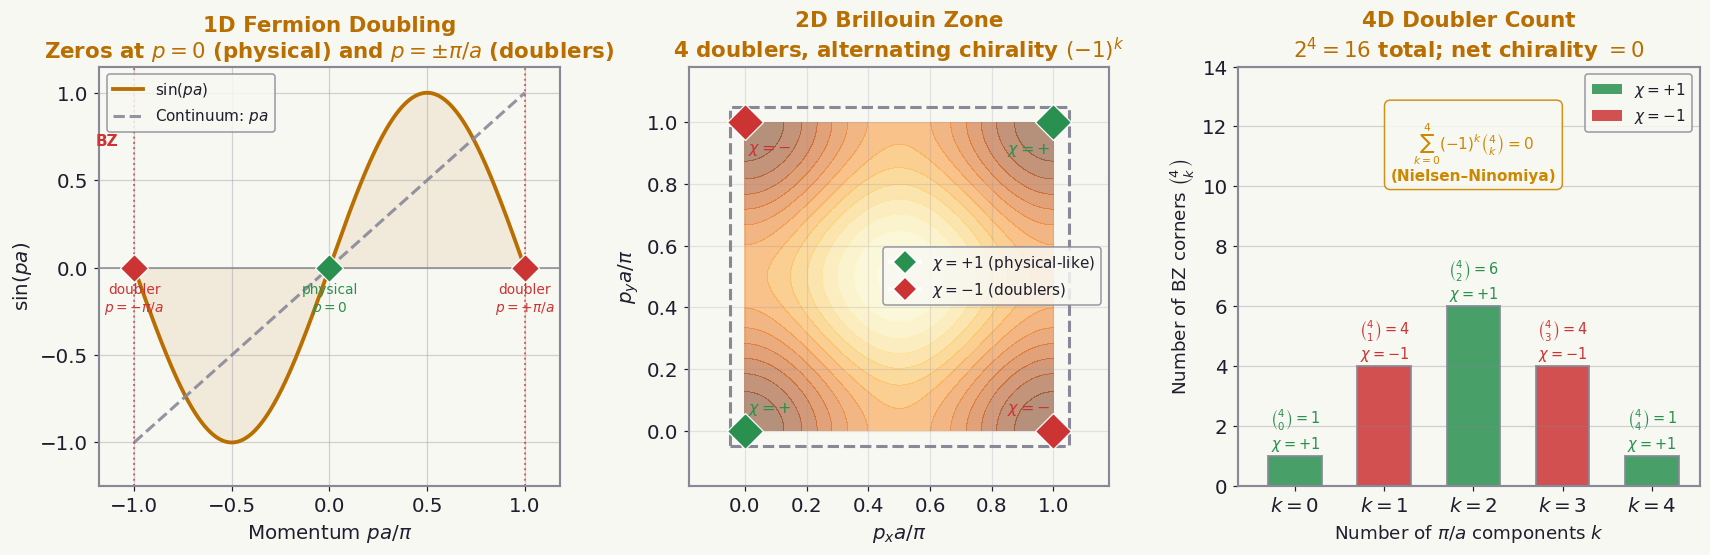

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: 1D dispersion ────────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

pa = np.linspace(-np.pi, np.pi, 500)
disp = np.sin(pa)

ax.plot(pa/np.pi, disp, color=AMBER, lw=2.5, label=r'$\sin(pa)$')
ax.plot(pa/np.pi, pa/np.pi, color=EDGE, lw=2, ls='--', alpha=0.9,
        label=r'Continuum: $pa$')
ax.fill_between(pa/np.pi, 0, disp, color=AMBER, alpha=0.10)

# 수정: 왼쪽 doubler는 p = -π/a
zeros_x  = [-1,     0,        +1]
zero_col  = [RED,   GREEN,    RED]
zero_lbl  = [r'doubler'+'\n'+r'$p=-\pi/a$',
             r'physical'+'\n'+r'$p=0$',
             r'doubler'+'\n'+r'$p=+\pi/a$']
for z, col, lbl in zip(zeros_x, zero_col, zero_lbl):
    ax.plot(z, 0, 'D', color=col, ms=13, zorder=5, mec='white', mew=0.8)
    ax.text(z, -0.25, lbl, ha='center', fontsize=9, color=col)

ax.axhline(0, color=EDGE, lw=1)
ax.axvline(-1, color=RED, lw=1.3, ls=':', alpha=0.7)
ax.axvline(+1, color=RED, lw=1.3, ls=':', alpha=0.7)
ax.text(-1.08, 0.7, 'BZ', ha='right', fontsize=10, color=RED, fontweight='bold')

ax.set_xlabel(r'Momentum $pa/\pi$', fontsize=13)
ax.set_ylabel(r'$\sin(pa)$', fontsize=13)
ax.set_title('1D Fermion Doubling\n'
             r'Zeros at $p=0$ (physical) and $p=\pm\pi/a$ (doublers)', color=AMBER)
ax.legend(fontsize=10)
ax.set_xlim(-1.18, 1.18); ax.set_ylim(-1.25, 1.15)
ax.grid(True, alpha=0.35)

# ── Middle: 2D Brillouin zone ──────────────────────────────────────────────
# 수정: chirality 레이블 위치를 경계 안쪽으로 조정
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_aspect('equal')

corners_2d = [
    (0, 0, 0),   # k=0, χ=+1
    (1, 0, 1),   # k=1, χ=-1
    (0, 1, 1),   # k=1, χ=-1
    (1, 1, 0),   # k=2, χ=+1
]

bz = Rectangle((-0.05, -0.05), 1.1, 1.1, fill=False, edgecolor=EDGE, lw=2, ls='--')
ax2.add_patch(bz)

p1 = np.linspace(0, np.pi, 100)
p2 = np.linspace(0, np.pi, 100)
P1g, P2g = np.meshgrid(p1/np.pi, p2/np.pi)
disp_2d = np.sin(p1[:,None])**2 + np.sin(p2[None,:])**2
ax2.contourf(P1g, P2g, disp_2d.T, levels=15, cmap='YlOrBr_r', alpha=0.5)

# 내부 방향으로 레이블 오프셋
chi_lbl_offsets = {(0,0): (+0.08, +0.07),
                   (1,0): (-0.08, +0.07),
                   (0,1): (+0.08, -0.09),
                   (1,1): (-0.08, -0.09)}
for px2, py2, k in corners_2d:
    col = GREEN if k==0 else RED
    ax2.plot(px2, py2, 'D', color=col, ms=17, zorder=5, mec='white', mew=0.8)
    dx, dy = chi_lbl_offsets[(px2, py2)]
    sign = '+' if k==0 else '-'
    ax2.text(px2+dx, py2+dy, fr'$\chi={sign}$', ha='center', va='center',
             fontsize=10.5, color=col, fontweight='bold')

ax2.set_xlabel(r'$p_x a/\pi$', fontsize=13)
ax2.set_ylabel(r'$p_y a/\pi$', fontsize=13)
ax2.set_title('2D Brillouin Zone\n' + r'4 doublers, alternating chirality $(-1)^k$', color=AMBER)
ax2.set_xlim(-0.18, 1.18); ax2.set_ylim(-0.18, 1.18)

legend_elems = [
    Line2D([0],[0], marker='D', color='w', markerfacecolor=GREEN, ms=11,
           label=r'$\chi=+1$ (physical-like)'),
    Line2D([0],[0], marker='D', color='w', markerfacecolor=RED, ms=11,
           label=r'$\chi=-1$ (doublers)'),
]
ax2.legend(handles=legend_elems, fontsize=10)
ax2.grid(True, alpha=0.2)

# ── Right: 4D doubler count ────────────────────────────────────────────────
# 수정: y축 상단 여유 확보, 레이블 겹침 방지
ax3 = axes[2]
ax3.set_facecolor(BG)

k_vals = np.arange(0, 5)
n_corners = [comb(4, k) for k in k_vals]
chirality_k = [(-1)**k for k in k_vals]

ax3.bar(k_vals, n_corners,
        color=[GREEN if (-1)**k > 0 else RED for k in k_vals],
        edgecolor=EDGE, lw=1.3, alpha=0.85, width=0.6)

for k, n, chi in zip(k_vals, n_corners, chirality_k):
    sign = '+' if chi > 0 else '-'
    ax3.text(k, n + 0.25,
             fr'$\binom{{4}}{{{k}}}={n}$' + '\n' + fr'$\chi={sign}1$',
             ha='center', fontsize=9.5, color=GREEN if chi>0 else RED)

contribution = [n * chi for n, chi in zip(n_corners, chirality_k)]
total = sum(contribution)
ax3.text(2.0, 10.2,
         r'$\sum_{k=0}^{4}(-1)^k\binom{4}{k}=' + str(total) + r'$' + '\n(Nielsen–Ninomiya)',
         ha='center', fontsize=10, color=YELLOW, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.4', facecolor=BG, edgecolor=YELLOW, alpha=0.9))

ax3.axhline(0, color=EDGE, lw=1)
ax3.set_xlabel(r'Number of $\pi/a$ components $k$', fontsize=12)
ax3.set_ylabel(r'Number of BZ corners $\binom{4}{k}$', fontsize=12)
ax3.set_title('4D Doubler Count\n' + r'$2^4=16$ total; net chirality $=0$', color=AMBER)
ax3.set_xticks(k_vals)
ax3.set_xticklabels([f'$k={k}$' for k in k_vals])
ax3.set_ylim(0, 14)

ax3.bar(0, 0, color=GREEN, label=r'$\chi=+1$', alpha=0.85)
ax3.bar(0, 0, color=RED,   label=r'$\chi=-1$', alpha=0.85)
ax3.legend(fontsize=10)
ax3.grid(True, axis='y', alpha=0.35)

plt.tight_layout(pad=1.8)
save('fig03_doubling.png', fig)


---
## fig04 · Domain Wall Fermions (§4.4.1)

**Left**: 5D domain wall geometry — mass profile $m(s)$  
**Middle**: Chiral zero mode profiles $f_L(s)$ and $f_R(s)$  
**Right**: Residual mass $m_{\rm res}$ vs $L_s$ — exponential suppression

  saved -> figures/ch04/fig04_domain_wall.png


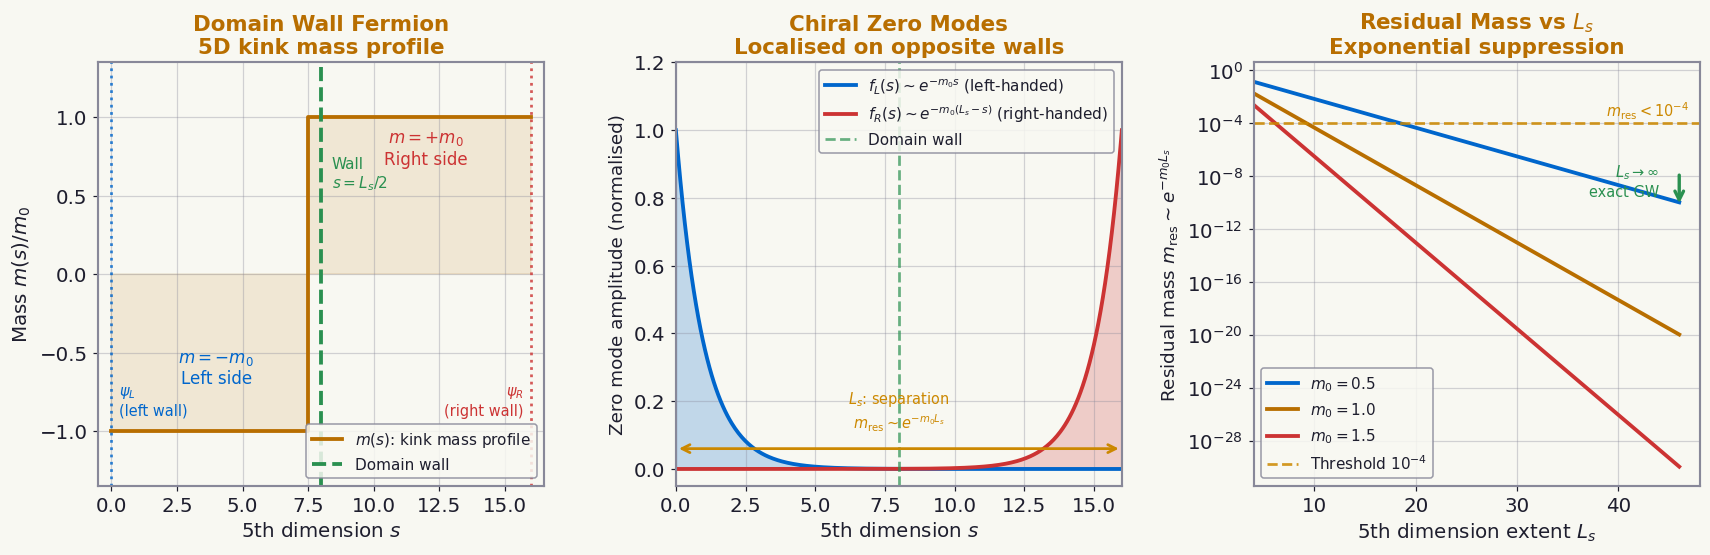

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

Ls = 16
m0 = 1.0

# ── Left: 5D geometry and mass profile ────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

s_arr = np.arange(0, Ls+1)
mass_profile = np.where(s_arr < Ls/2, -m0, +m0)

ax.step(s_arr, mass_profile, color=AMBER, lw=2.5, where='mid',
        label=r'$m(s)$: kink mass profile')
ax.fill_between(s_arr, 0, mass_profile, color=AMBER, alpha=0.12, step='mid')

ax.axvline(Ls/2, color=GREEN, lw=2.5, ls='--', label='Domain wall')
ax.text(Ls/2+0.4, 0.55, 'Wall\n$s=L_s/2$', fontsize=10, color=GREEN)

ax.text(Ls/4, -0.7, r'$m=-m_0$' + '\nLeft side', ha='center', fontsize=11, color=BLUE)
ax.text(3*Ls/4, 0.7, r'$m=+m_0$' + '\nRight side', ha='center', fontsize=11, color=RED)

ax.axvline(0, color=BLUE, lw=1.8, ls=':', alpha=0.8)
ax.axvline(Ls, color=RED, lw=1.8, ls=':', alpha=0.8)
# 수정: \n을 실제 줄바꿈으로
ax.text(0.3, -0.9, '$\\psi_L$\n(left wall)', fontsize=9.5, color=BLUE)
ax.text(Ls-0.3, -0.9, '$\\psi_R$\n(right wall)', ha='right', fontsize=9.5, color=RED)

ax.set_xlabel(r'5th dimension $s$', fontsize=13)
ax.set_ylabel(r'Mass $m(s)/m_0$', fontsize=13)
ax.set_title('Domain Wall Fermion\n5D kink mass profile', color=AMBER)
ax.set_xlim(-0.5, Ls+0.5)
ax.set_ylim(-1.35, 1.35)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.35)

# ── Middle: zero mode profiles ─────────────────────────────────────────────
# 수정: m_res 양방향 화살표를 0~Ls 전체로 수정 (overlap은 두 모드 사이의 거리)
ax2 = axes[1]
ax2.set_facecolor(BG)

s_cont = np.linspace(0, Ls, 400)
f_L = np.exp(-m0 * s_cont); f_L /= f_L.max()
f_R = np.exp(-m0 * (Ls - s_cont)); f_R /= f_R.max()

ax2.fill_between(s_cont, 0, f_L, color=BLUE, alpha=0.22)
ax2.fill_between(s_cont, 0, f_R, color=RED, alpha=0.22)
ax2.plot(s_cont, f_L, color=BLUE, lw=2.5,
         label=r'$f_L(s)\sim e^{-m_0 s}$ (left-handed)')
ax2.plot(s_cont, f_R, color=RED, lw=2.5,
         label=r'$f_R(s)\sim e^{-m_0(L_s-s)}$ (right-handed)')

ax2.axvline(Ls/2, color=GREEN, lw=1.8, ls='--', alpha=0.7, label='Domain wall')

# 수정: 분리 거리 = Ls (0에서 Ls까지), residual mass ∝ overlap ∝ e^{-m0 Ls}
ax2.annotate('', xy=(Ls, 0.06), xytext=(0, 0.06),
             arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.8))
ax2.text(Ls/2, 0.12, r'$L_s$: separation' + '\n' + r'$m_{\rm res}\sim e^{-m_0 L_s}$',
         fontsize=9.5, color=YELLOW, ha='center')

ax2.set_xlabel(r'5th dimension $s$', fontsize=13)
ax2.set_ylabel('Zero mode amplitude (normalised)', fontsize=12)
ax2.set_title('Chiral Zero Modes\nLocalised on opposite walls', color=AMBER)
ax2.set_xlim(0, Ls); ax2.set_ylim(-0.05, 1.2)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.35)

# ── Right: Residual mass vs Ls ─────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

Ls_vals = np.arange(4, 48, 2)
m0_vals = [0.5, 1.0, 1.5]
colors_m0 = [BLUE, AMBER, RED]

for m0_v, col in zip(m0_vals, colors_m0):
    m_res = np.exp(-m0_v * Ls_vals)
    ax3.semilogy(Ls_vals, m_res, color=col, lw=2.5,
                 label=f'$m_0={m0_v}$')

ax3.axhline(1e-4, color=YELLOW, lw=1.8, ls='--', alpha=0.85, label=r'Threshold $10^{-4}$')
ax3.text(47, 3e-4, r'$m_{\rm res}<10^{-4}$', ha='right', fontsize=9.5, color=YELLOW)

ax3.annotate('', xy=(46, 5e-11), xytext=(46, 2e-8),
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.2, mutation_scale=14))
ax3.text(44, 3e-10, r'$L_s\to\infty$' + '\nexact GW', ha='right', fontsize=9.5, color=GREEN)

ax3.set_xlabel(r'5th dimension extent $L_s$', fontsize=13)
ax3.set_ylabel(r'Residual mass $m_{\rm res}\sim e^{-m_0 L_s}$', fontsize=12)
ax3.set_title(r'Residual Mass vs $L_s$' + '\nExponential suppression', color=AMBER)
ax3.legend(fontsize=10)
ax3.set_xlim(4, 48)
ax3.grid(True, which='both', alpha=0.35)

plt.tight_layout(pad=1.8)
save('fig04_domain_wall.png', fig)


---
## fig05 · Ginsparg-Wilson Relation (§4.4.3)

**Left**: GW circle in the complex plane — eigenvalues of $aD_{\rm ov}$ lie on unit circle  
**Middle**: Lattice index theorem — index of $D_{\rm ov}$ vs topological charge $Q$  
**Right**: Additive mass renormalisation: Wilson vs overlap/GW

  saved -> figures/ch04/fig05_ginsparg_wilson.png


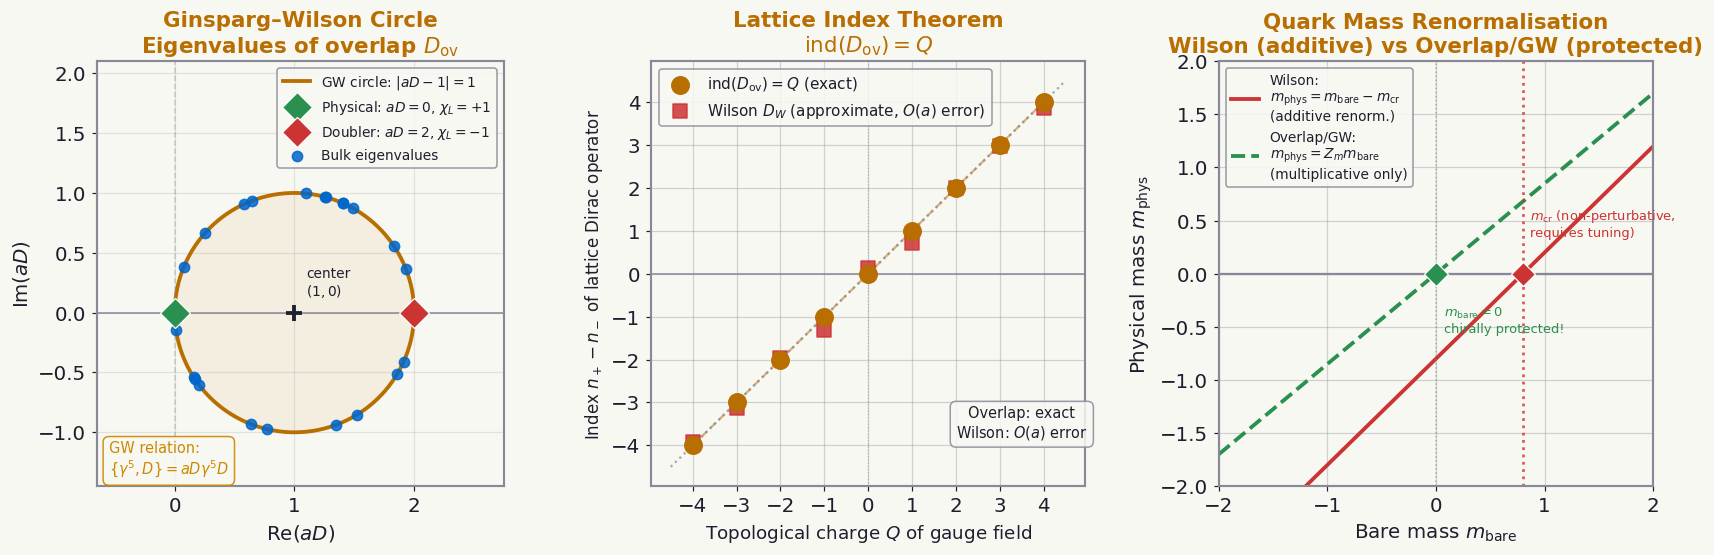

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: GW circle ────────────────────────────────────────────────────────
# GW relation: {γ5, D} = a D γ5 D
# For overlap D_ov = (1/a)(1 + A/sqrt(A†A)) with A=D_W - 1/a:
# eigenvalues of aD_ov lie on circle |z-1|=1 centred at (1,0) in complex plane
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')

theta_circ = np.linspace(0, 2*np.pi, 400)
x_circle = 1 + np.cos(theta_circ)
y_circle = np.sin(theta_circ)
ax.plot(x_circle, y_circle, color=AMBER, lw=2.5,
        label=r'GW circle: $|aD-1|=1$')
ax.fill_between(x_circle, y_circle, 0,
                where=(np.abs(np.angle(x_circle - 1 + 1j*y_circle)) < np.pi),
                color=AMBER, alpha=0.07)

ax.axhline(0, color=EDGE, lw=1)
ax.axvline(0, color=EDGE, lw=1, ls='--', alpha=0.4)

# Physical zero (aD=0) and doubler (aD=2)
ax.plot(0, 0, 'D', color=GREEN, ms=14, zorder=5, mec='white', mew=0.8,
        label=r'Physical: $aD=0$, $\chi_L=+1$')
ax.plot(2, 0, 'D', color=RED,   ms=14, zorder=5, mec='white', mew=0.8,
        label=r'Doubler: $aD=2$, $\chi_L=-1$')

np.random.seed(42)
n_eigs = 22
theta_eigs = np.random.uniform(0.25, 2*np.pi-0.25, n_eigs)
ax.scatter(1 + np.cos(theta_eigs), np.sin(theta_eigs),
           color=BLUE, s=45, zorder=4, alpha=0.85,
           label='Bulk eigenvalues')

ax.plot(1, 0, '+', color=FG, ms=10, mew=2.5)
ax.text(1.1, 0.14, 'center\n$(1,0)$', fontsize=9, color=FG)

ax.text(-0.55, -1.35,
        'GW relation:\n' + r'$\{\gamma^5, D\} = a D\gamma^5 D$',
        fontsize=9.5, color=YELLOW,
        bbox=dict(boxstyle='round,pad=0.4', facecolor=BG, edgecolor=YELLOW, alpha=0.9))

ax.set_xlabel(r'Re$(aD)$', fontsize=13)
ax.set_ylabel(r'Im$(aD)$', fontsize=13)
ax.set_title('Ginsparg–Wilson Circle\nEigenvalues of overlap $D_{\\rm ov}$', color=AMBER)
ax.legend(fontsize=9, loc='upper right')
ax.set_xlim(-0.65, 2.75); ax.set_ylim(-1.45, 2.1)
ax.grid(True, alpha=0.2)

# ── Middle: Lattice index theorem ──────────────────────────────────────────
# 수정: Wilson scatter noise 감쇠를 0.25→0.18로 줄여 int 근처에 유지
ax2 = axes[1]
ax2.set_facecolor(BG)

Q_range = np.arange(-4, 5)
index_ov = Q_range

ax2.scatter(Q_range, index_ov, color=AMBER, s=130, zorder=5,
            label=r'$\mathrm{ind}(D_{\rm ov}) = Q$ (exact)')
ax2.plot(Q_range, index_ov, color=AMBER, lw=1.5, ls='--', alpha=0.5)

np.random.seed(12)
noise_W = np.random.normal(0, 0.18, len(Q_range))
ax2.scatter(Q_range, index_ov + noise_W, color=RED, s=85, marker='s', zorder=4,
            alpha=0.85, label=r'Wilson $D_W$ (approximate, $O(a)$ error)')

ax2.plot([-4.5, 4.5], [-4.5, 4.5], color=EDGE, lw=1.5, ls=':', alpha=0.7)
ax2.axhline(0, color=EDGE, lw=1)
ax2.axvline(0, color=EDGE, lw=0.8, ls=':', alpha=0.5)

ax2.text(3.5, -3.8,
         'Overlap: exact\nWilson: $O(a)$ error',
         fontsize=9.5, color=FG, ha='center',
         bbox=dict(boxstyle='round,pad=0.4', facecolor=BG, edgecolor=EDGE, alpha=0.85))

ax2.set_xlabel(r'Topological charge $Q$ of gauge field', fontsize=12)
ax2.set_ylabel(r'Index $n_+ - n_-$ of lattice Dirac operator', fontsize=11)
ax2.set_title('Lattice Index Theorem\n' + r'$\mathrm{ind}(D_{\rm ov}) = Q$', color=AMBER)
ax2.set_xticks(Q_range); ax2.set_yticks(Q_range)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.35)

# ── Right: Mass renormalisation comparison ─────────────────────────────────
# 수정: "m_cr is non-perturbative, requires tuning" 주석 강화
ax3 = axes[2]
ax3.set_facecolor(BG)

m_bare = np.linspace(-2, 2, 400)
m_cr_W = 0.8
m_phys_W  = m_bare - m_cr_W
Z_m = 0.85
m_phys_ov = Z_m * m_bare

ax3.plot(m_bare, m_phys_W,  color=RED,   lw=2.5,
         label='Wilson:\n$m_{\\rm phys}=m_{\\rm bare}-m_{\\rm cr}$\n(additive renorm.)')
ax3.plot(m_bare, m_phys_ov, color=GREEN, lw=2.5, ls='--',
         label='Overlap/GW:\n$m_{\\rm phys}=Z_m m_{\\rm bare}$\n(multiplicative only)')

ax3.axhline(0, color=EDGE, lw=1.5)
ax3.axvline(0, color=EDGE, lw=1, ls=':', alpha=0.6)

ax3.axvline(m_cr_W, color=RED, lw=1.8, ls=':', alpha=0.8)
ax3.plot(m_cr_W, 0, 'D', color=RED, ms=11, zorder=5, mec='white', mew=0.8)
ax3.text(m_cr_W + 0.07, 0.35,
         r'$m_{\rm cr}$ (non-perturbative,' + '\nrequires tuning)',
         fontsize=8.5, color=RED)

ax3.plot(0, 0, 'D', color=GREEN, ms=11, zorder=5, mec='white', mew=0.8)
ax3.text(0.07, -0.55,
         r'$m_{\rm bare}=0$' + '\nchirally protected!',
         fontsize=8.5, color=GREEN)

ax3.set_xlabel(r'Bare mass $m_{\rm bare}$', fontsize=13)
ax3.set_ylabel(r'Physical mass $m_{\rm phys}$', fontsize=13)
ax3.set_title('Quark Mass Renormalisation\nWilson (additive) vs Overlap/GW (protected)',
              color=AMBER)
ax3.legend(fontsize=9, loc='upper left')
ax3.set_xlim(-2, 2); ax3.set_ylim(-2, 2)
ax3.grid(True, alpha=0.35)

plt.tight_layout(pad=1.8)
save('fig05_ginsparg_wilson.png', fig)


---
## Download figures

In [7]:
import shutil
from google.colab import files

shutil.make_archive('gauge_ch04_figures', 'zip', '.', 'figures')
files.download('gauge_ch04_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Checklist

| File | Content | Status |
|------|---------|--------|
| `fig01_lattice_scalar.png`   | Lattice geometry / dispersion / continuum limit | ☐ |
| `fig02_strong_coupling.png`  | Plaquette tiling / string tension / area law | ☐ |
| `fig03_doubling.png`         | 1D dispersion / 2D BZ chirality / 4D count | ☐ |
| `fig04_domain_wall.png`      | 5D geometry / zero mode profiles / $m_{\rm res}$ vs $L_s$ | ☐ |
| `fig05_ginsparg_wilson.png`  | GW circle / lattice index theorem / mass renorm | ☐ |